In [6]:
import numpy as np;
import matplotlib.pyplot as plt

In [2]:
x=np.array([1.0,2.0,3.0])
y=np.array([4.0,2.0,6.0])
x+y


array([5., 4., 9.])

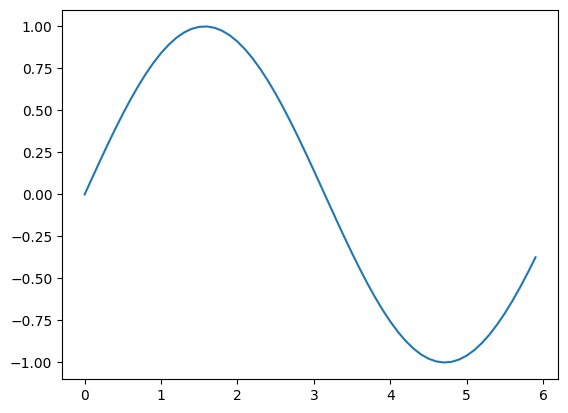

In [7]:
x= np.arange(0,6,0.1)
y=np.sin(x)
plt.plot(x,y)
plt.show()

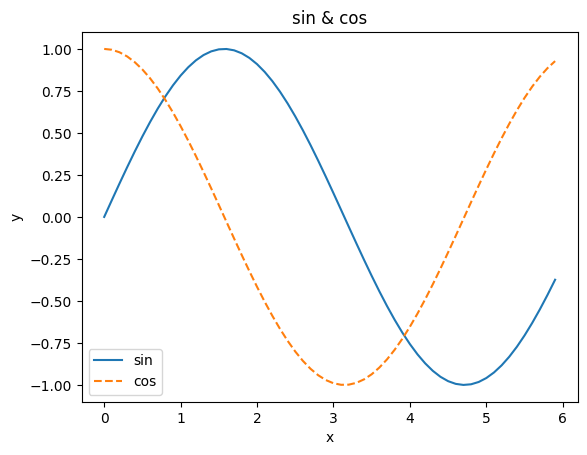

In [10]:
x=np.arange(0,6,0.1)
y1=np.sin(x)
y2=np.cos(x)
plt.plot(x,y1,label="sin")
plt.plot(x,y2,linestyle="--",label="cos")
plt.xlabel("x")
plt.ylabel("y")
plt.title('sin & cos')
plt.legend()
plt.show()


In [15]:
x=np.array([-1.0,1.0,2.0])
x
y=x>0
y=y.astype(int)
y

array([0, 1, 1])

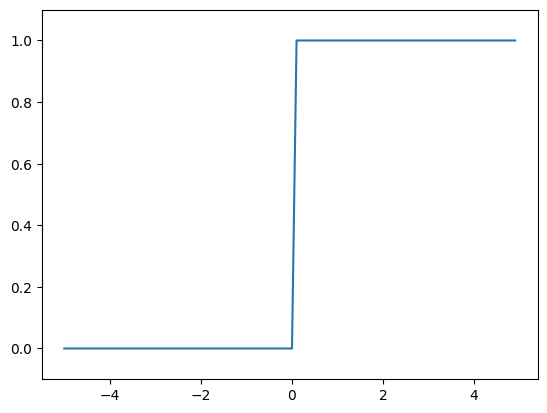

In [16]:
def step_function(x):
    return np.array(x>0,dtype=int)
x=np.arange(-5.0,5.0,0.1)
y=step_function(x)
plt.plot(x,y)
plt.ylim(-0.1,1.1)
plt.show()

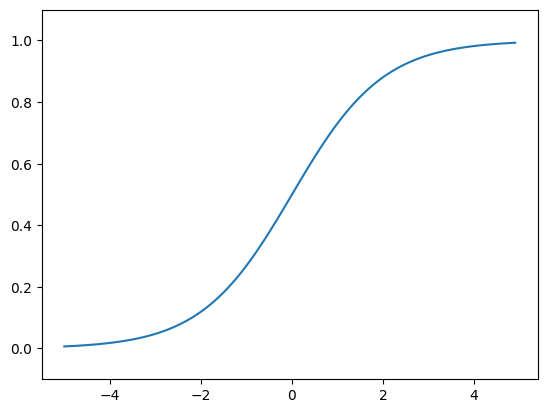

In [19]:
def sigmoid(x):
    return 1/(1+np.exp(-x))
    
x=np.arange(-5.0,5.0,0.1)
y= sigmoid(x)
plt.plot(x,y)
plt.ylim(-0.1,1.1)
plt.show()

In [ ]:
def relu(x):
    return np.maximum(0,x)

In [24]:
A=np.array([1,2,3,4])
print(A)
print(np.ndim(A))
print(A.shape)
print(A[0].shape)

[1 2 3 4]
1
(4,)
()


In [30]:
def init_network():
    network={}
    network['W1']=np.array([[0.1,0.3,0.5],[0.2,0.4,0.6]])
    network['B1']=np.array([0.1,0.2,0.3])
    network['W2']=np.array([[0.1,0.4],[0.2,0.5],[0.3,0.6]])
    network['B2']=np.array([0.1,0.2])
    network['W3']=np.array([[0.1,0.3],[0.2,0.4]])
    network['B3']=np.array([0.1,0.2])
    return network

def forward(network,x):
    W1,W2,W3=network['W1'],network['W2'],network['W3']
    b1,b2,b3=network['B1'],network['B2'],network['B3']
    a1=np.dot(x,W1)+b1
    z1=sigmoid(a1)
    a2=np.dot(z1,W2)+b2
    z2=sigmoid(a2)
    a3=np.dot(z2,W3)+b3
    return a3

network=init_network()
x= np.array([1.0,0.5])
y= forward(network,x)
print(y)


[0.31682708 0.69627909]


In [31]:
a=np.array([0.3,2.9,4.0])
exp_a=np.exp(a)
sum_exp_a=sum(exp_a)
print(exp_a/sum_exp_a)

[0.01821127 0.24519181 0.73659691]


In [32]:
def softmax(a):
    c=np.max(a)
    exp_a=np.exp(a-c)
    sum_exp_a=np.sum(exp_a)
    return exp_a/sum_exp_a

In [ ]:
def sum_squares_error(y,t):
    return 0.5*np.sum((y-t)**2)

In [ ]:
def cross_entropy_error(y,t):
    delta=1e-7
    return -np.sum(t*np.log(y+delta))

In [6]:
import sys,os
import numpy as np
from tensorflow.keras.datasets import mnist

(x_train,t_train),(x_test,t_test)=mnist.load_data()
print(x_train.shape)

(60000, 28, 28)


In [ ]:
train_size=x_train.shape[0]
batch_size=10
batch_mask=np.random.choice(train_size,batch_size)
x_batch=x_train[batch_mask]
t_batch=t_train[batch_mask]


In [ ]:
def cross_entropy_error(y,t):
    if y.dim==1:
        t=t.reshape(1,t.size)
        y=y.reshape(1,y.size)
    batch_size=y.shape[0]
    return -np.sum(t*np.log(y+1e-7))/batch_size

In [ ]:
def cross_entropy_error(y,t):
    if y.dim==1:
        t=t.reshape(1,t.size)
        y=y.reshape(1,y.size)
    batch_size=y.shape[0]
    return -np.sum(np.log(y[np.arange(batch_size),t]+1e-7))/batch_size

In [ ]:
def numercial_gradient(f,x):
    h=1e-4
    grad=np.zeros_like(x)
    for idx in range(x.size):
        tmp_val=x[idx]
        x[idx]=tmp_val+h
        fxh1=f(x)
        x[idx]=tmp_val-h
        fxh2=f(x)
        grad[idx]=(fxh1-fxh2)/(2*h)
        x[idx]=tmp_val
    return grad
    

In [ ]:
def gradient_descent(f,init_x,lr=0.01,step_num=100):
    x=init_x
    for i in range(step_num):
        grad=numercial_gradient(f,x)
        x-=lr*grad
    return x

In [ ]:
def function_2(x):
    return x[0]**2+x[1]**2
init_x=np.array([-3.0,4.0])
gradient_descent(function_2,init_x=init_x,lr=0.1,step_num=100)